In [1]:
import cobaya
import numpy as np
import matplotlib.pyplot as plt
from cobaya.run import run
from cobaya.samplers.mcmc import plot_progress
from astropy.cosmology import FlatLambdaCDM, LambdaCDM
from getdist.mcsamples import MCSamplesFromCobaya, MCSamples
import getdist.plots as gdplt

import emcee
from cobaya.run import run

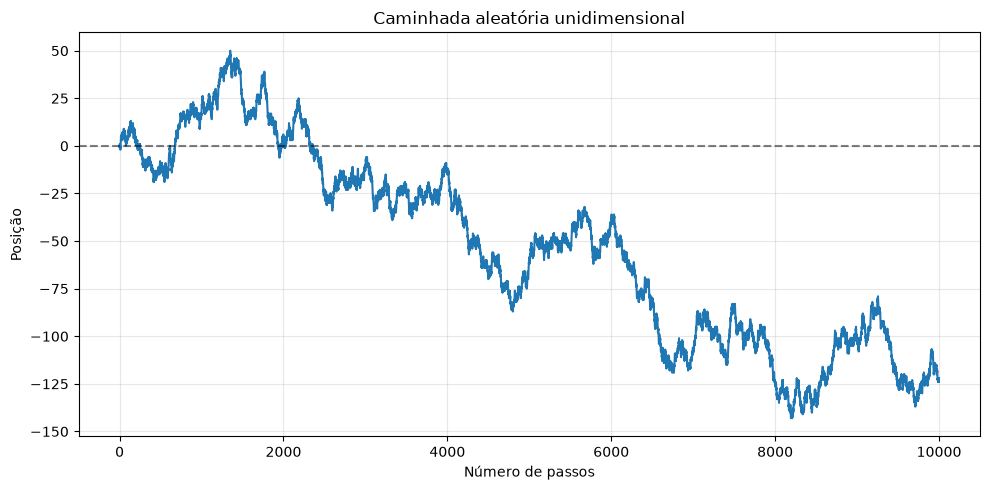

In [2]:
# Parâmetros
n_steps = 10000
x0 = 0

# Gerar os passos: -1 (esquerda) ou +1 (direita)
rng = np.random.default_rng(seed=42)
steps = rng.choice([-1, 1], size=n_steps)

# Posição ao longo do tempo
x = np.concatenate([[x0], x0 + np.cumsum(steps)])

# Gráfico da trajetória
plt.figure(figsize=(10, 5))
plt.plot(np.arange(n_steps + 1), x)
plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.xlabel("Número de passos")
plt.ylabel("Posição")
plt.title("Caminhada aleatória unidimensional")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Metropolis Hastings

## Motivação

Queremos a distribuição *a posteriori* dos parâmetros $\theta$ dados os dados $d$:

$$
\pi(\theta) \;=\; p(\theta \mid d) \;=\; \frac{\mathcal{L}(d \mid \theta)\, p(\theta)}{Z},
\qquad Z = \int \mathcal{L}(d \mid \theta)\, p(\theta)\, d\theta .
$$

Em geral sabemos calcular o numerador $\mathcal{L}(d \mid \theta)\,p(\theta)$ para qualquer $\theta$, mas a constante de normalização $Z$ (a *evidência*) é uma integral em muitas dimensões, cara ou impossível de calcular. Em vez de tentar integrar, o que fazemos é **gerar amostras** de $\pi$. Com elas, qualquer resumo do posterior (média, intervalo de confiança, distribuição marginal) vira uma conta simples sobre as amostras.

O Metropolis-Hastings (MH) é o algoritmo mais básico para isso, e a base de muitos outros métodos MCMC (*Markov chain Monte Carlo*).

## A ideia: uma caminhada aleatória com filtro

Construímos uma sequência $\theta_0, \theta_1, \theta_2, \dots$ em que cada ponto depende apenas do anterior (uma **cadeia de Markov**) e cuja distribuição de longo prazo é $\pi$. A cadeia dá passos aleatórios, mas com uma regra que favorece regiões de maior probabilidade, na medida certa para que o tempo gasto em cada região seja proporcional a $\pi$.

## O algoritmo

Dado o ponto atual $\theta$:

1. **Propor** um novo ponto $\theta' \sim q(\theta' \mid \theta)$, a *distribuição de proposta* (por exemplo, uma gaussiana centrada em $\theta$).
2. **Calcular a razão de aceitação**:

$$
\alpha(\theta, \theta') \;=\; \min\!\left(1,\; \frac{\pi(\theta')\, q(\theta \mid \theta')}{\pi(\theta)\, q(\theta' \mid \theta)}\right).
$$

3. **Aceitar** $\theta'$ com probabilidade $\alpha$ (a cadeia vai para $\theta'$). Caso contrário, **rejeitar**: a cadeia **repete** $\theta$.

Se a proposta é simétrica, $q(\theta' \mid \theta) = q(\theta \mid \theta')$ (o caso de uma gaussiana centrada no ponto atual), os termos de $q$ se cancelam e sobra o algoritmo original de Metropolis (1953):

$$
\alpha = \min\!\left(1,\; \frac{\pi(\theta')}{\pi(\theta)}\right).
$$

Três observações:

- Um passo para uma região **mais provável** ($\pi(\theta') \ge \pi(\theta)$) é sempre aceito. Um passo para uma região **menos provável** é aceito às vezes, e é isso que permite explorar as caudas.
- Só aparecem **razões** de $\pi$, então a constante $Z$ desaparece. Basta conhecer $\pi$ a menos de uma constante.
- Quando um ponto é rejeitado, ele é **repetido** na cadeia, e essa repetição conta. Descartar os repetidos distorceria a distribuição.

Na prática trabalha-se com logaritmos: aceita-se se $\log u < \log\pi(\theta') - \log\pi(\theta)$, com $u \sim U(0,1)$.

## Por que funciona: balanço detalhado

Seja $K(\theta \to \theta')$ o núcleo de transição da cadeia. Dizemos que ela satisfaz o **balanço detalhado** (é *reversível*) em relação a $\pi$ se

$$
\pi(\theta)\, K(\theta \to \theta') \;=\; \pi(\theta')\, K(\theta' \to \theta).
$$

Isso diz que o fluxo de probabilidade de $\theta$ para $\theta'$ é igual ao fluxo no sentido contrário, para cada par de pontos. Integrando os dois lados em $\theta$, obtém-se $\int \pi(\theta)K(\theta\to\theta')\,d\theta = \pi(\theta')$, isto é, **$\pi$ é estacionária**: se a cadeia está distribuída como $\pi$, continua assim.

No MH, $K(\theta \to \theta') = q(\theta' \mid \theta)\,\alpha(\theta, \theta')$, e a regra de aceitação foi escolhida justamente para satisfazer essa igualdade. Junto com **ergodicidade** (a cadeia consegue alcançar qualquer região de probabilidade positiva), isso garante que, para tempo suficientemente longo, as amostras seguem $\pi$ e as médias ao longo da cadeia convergem para as esperanças sob $\pi$.

## Qualidade da cadeia

### A escala da proposta

É o ajuste mais importante:

- **Passo pequeno demais:** quase tudo é aceito, mas a cadeia anda devagar (um *random walk* de passos curtos) e as amostras ficam muito correlacionadas.
- **Passo grande demais:** quase tudo é rejeitado e a cadeia fica parada.

### Correlações entre parâmetros

Se os parâmetros são correlacionados e a proposta é isotrópica (mesmo passo em todas as direções), o passo precisa ser pequeno para não sair da região estreita onde está a probabilidade. A solução padrão é usar a **matriz de covariância** do posterior na proposta. Como ela não é conhecida de antemão, muitos programas a **aprendem durante a execução** (MH *adaptativo*; o Cobaya faz isso).

### Autocorrelação e tamanho efetivo

Pontos consecutivos da cadeia são correlacionados, porque cada um nasce do anterior. Isso reduz a informação: $N$ passos valem por apenas

$$
\mathrm{ESS} = \frac{N}{\tau}
$$

amostras independentes, em que $\tau$ é o **tempo de autocorrelação integrado**. O erro Monte Carlo de uma média depende do ESS, não de $N$.

## Na prática

- **Burn-in.** Descarte o trecho inicial, antes de a cadeia chegar à região típica de $\pi$.
- **Convergência.** Rode várias cadeias a partir de pontos dispersos e compare-as (teste de Gelman-Rubin, $\hat R \to 1$). Nenhum teste prova convergência, só detecta falhas.
- **Inspecione as cadeias.** Gráficos podem revelar problemas.

## Limitações

- **Alta dimensão e degenerescências fortes** tornam o passeio lento. Existem propostas mais inteligentes (ensemble samplers, HMC).
- **Distribuições multimodais:** a cadeia pode ficar presa em um modo, e várias cadeias presas no mesmo modo ainda podem "concordar" entre si. Nesses casos usam-se métodos como *nested sampling* ou *parallel tempering*.
- **Curvaturas não lineares** (distribuições em forma de banana) obrigam a passos pequenos.

# Gelma-Rubin

https://arxiv.org/html/1812.09384v3

Como saber se a cadeia convergiu?

Uma cadeia MCMC produz amostras da distribuição alvo depois de “esquecer” o ponto inicial e chegar à região típica. Não há um teste que prove convergência, mas é possível procurar sinais de que ela falhou. Uma cadeia pode parecer estável por varios passos e estar presa numa região, sem que nada no gráfico dela denuncie isso.

A ideia de Gelman e Rubin (1992) é comparar várias cadeias. Se partimos de pontos iniciais bem espalhados e as cadeias convergiram, todas devem ter explorado a mesma distribuição e ficar estatisticamente indistinguíveis.

Como é calculado?

Rodam-se $m$ cadeias, cada uma com $n$ passos (já sem o burn-in), para um parâmetro $\theta$. Seja $\bar{\theta}_j$ a média da cadeia $j$, $\bar{\theta}$ a média geral e $s_j^2$ a variância dentro da cadeia $j$. Definimos duas quantidades.

Variância dentro das cadeias $W$ e entre as cadeias $B/n$
$$ W = \frac{1}{m} \sum_j s_j^2 $$
$$ B/n = \frac{1}{m-1} \sum_j (\bar{\theta}_j - \bar{\theta})^2 $$

- $W$ costuma subestimar a variância se as cadeias ainda não exploraram tudo, porque cada uma cobriu só uma parte.
- $V$ = (n−1)/n · W + B/n tende a superestimar se os pontos iniciais eram bem dispersos, porque as médias ainda diferem entre si.

O teste é a razão $\hat{R}=\sqrt{V/W}$

Assim se as cadeias convergiram, as duas estimativas coincidem e $\hat{R}$ tende a 1. Se não, $V>W$ e $\hat{R}>1$.

Como se interpreta?

- $\hat{R} \approx 1$: as cadeias concordam entre si.
- Não há um limite universal estabelicido para se conformar com um valor de $\hat{R}$. Eu tenho visto que costuma-se pedir $R−1 < 0.01$ as vezes pode ser usado $0.05$, depende do caso.
- um valor alto de $\hat{R}$ indica que é preciso rodar mais, ou que as cadeias estão presas em regiões diferentes, ou que a proposta está mal ajustada.


# Cobaya

https://cobaya.readthedocs.io/_/downloads/en/stable/pdf/?utm_source=chatgpt.com

In [3]:
print(cobaya.likelihood.__file__)

/home/igorstellet/research/lib/python3.14/site-packages/cobaya/likelihood.py


### Aprendizado adaptativo da proposta

O Cobaya usa uma proposta gaussiana cuja matriz de covariância é **aprendida durante a execução**. Com `learn_proposal: True`, de tempos em tempos o sampler estima a covariância empírica da cadeia (descartando o início) e a usa como nova proposta. Uma covariância já conhecida pode ser fornecida com a opção `covmat`.

Uma cadeia que muda a proposta continuamente não é markoviana, e o balanço detalhado deixa de valer. Por isso a adaptação só acontece enquanto a convergência ainda é grosseira (critério baseado em $R-1$), e depois a proposta fica fixa.

### Parâmetros rápidos e lentos

Em cosmologia, alterar os parâmetros cosmológicos exige rodar um código de Boltzmann (CAMB ou CLASS), que é lento. Já os parâmetros de *nuisance* das likelihoods (calibração, foregrounds) são baratos, porque o espectro teórico fica em cache. O Cobaya mede a velocidade de cada bloco de parâmetros (`measure_speeds`), agrupa-os por custo e propõe passos por bloco. Os blocos rápidos recebem muito mais passos por passo lento (*oversampling*, controlado por `oversample_power`), de modo que o espaço dos parâmetros baratos é explorado sem pagar o código de Boltzmann a cada passo.

### Dragging

O *oversampling* simples funciona mal quando os parâmetros rápidos são fortemente correlacionados com os lentos: ao mover um parâmetro lento, os rápidos ficam "para trás" e o novo ponto tem baixa probabilidade, sendo rejeitado. No *dragging*, com `drag: True`, o passo lento é acompanhado por uma sequência de passos intermediários nos parâmetros rápidos, que são arrastados ao longo do caminho. A aceitação final leva em conta todo o trajeto, o que preserva o balanço detalhado. O resultado é que passos lentos maiores continuam sendo aceitos com frequência razoável.

### Convergência e múltiplas cadeias

Já oferece um teste de Gelman-Rubin e para de rodar quando o coeficiente R-1 alcançar o valor `Rminus1_stop`, caso for usado.
No caso de ter apenas um caminhante, o pacote divide a cadeia em 5 partes iguais descartando a primeira e usando as quatro restantes como cadeias independentes para calcular R-1.

### O ecossistema cobaya

Estrutura em blocos com clases, integra diferentes likelihoods aproveitando tempo de computo.

### Desvantagens
- Estrutura rigida e "complexa" - perda de liberdade.
- sampler mcmc pode ser poco eficiente para nao gaussianidades muito fortes ou likelihoods demoradas.

In [4]:
mean = np.array([0.5, -1.0])
cov = np.array([[1.0, 0.9],
                [0.9, 1.0]])
icov = np.linalg.inv(cov)

def loglike(x, y):
    d = np.array([x, y]) - mean
    return -0.5 * d @ icov @ d

Veremos:

- `proposal`: tamanho de passo inicial, usado até aprender a nova covariancia.
- `learn_proposal`: muda a proposal periodicamente a partir da covariancia da cadeia.
- `Rminus1_stop`: para de rodar quando o Gelman-Rubin $R-1$ cair abaixo de um valor dado.

In [35]:
# mudar prior, ref, proposal
info = {
    "likelihood": {"gauss": loglike},
    "params": {
        "x": {"prior": {"min": -10, "max": 10 }, "ref": 5, "proposal": 0.5 , "latex": "x"},
        "y": {"prior": {"min": -10 , "max": 10 }, "ref": 5, "proposal": 0.5 , "latex": "y"},
    },
    "sampler": {"mcmc": {
        "learn_proposal": True,
        "Rminus1_stop": 0.01,
        "max_samples": 50000,
    }},
    "output": "results_ex1/exemplo1",
    "force": True,
}

updated_info, sampler = run(info)

INFO:output:Output to be read-from/written-into folder 'results_ex1', with prefix 'exemplo1'


[output] Output to be read-from/written-into folder 'results_ex1', with prefix 'exemplo1'


INFO:output:Found existing info files with the requested output prefix: 'results_ex1/exemplo1'


[output] Found existing info files with the requested output prefix: 'results_ex1/exemplo1'


INFO:output:Will delete previous products ('force' was requested).


...

[mcmc]  - Convergence of bounds: R-1 = 0.066585 after 1920 accepted steps


INFO:mcmc:The run has converged!


[mcmc] The run has converged!


INFO:mcmc:Sampling complete after 1920 accepted steps.


[mcmc] Sampling complete after 1920 accepted steps.


Cobaya salva pontos repetidos (propostas rejeitadas) como uma fila de dados com um inteiro associado ou **peso**. Para alguns usos é preciso 'expandir' a cadeia repetindo pasos (analogo a ter pesos unitarios).

In [36]:
samples = sampler.products()["sample"]
df = samples.data
print("Filas (pontos diferentes):", len(df))
print("Passos totais (soma pesada):", int(df["weight"].sum()))
print("Acceptance rate:", len(df) / df["weight"].sum())

# "Expandir os pesos" -> Cadeia completa, uma fila por passo
w = df["weight"].values.astype(int)
chain = np.repeat(df[["x", "y"]].values, w, axis=0)
chain.shape

Filas (pontos diferentes): 1920
Passos totais (soma pesada): 5982
Acceptance rate: 0.320962888665998


(5982, 2)

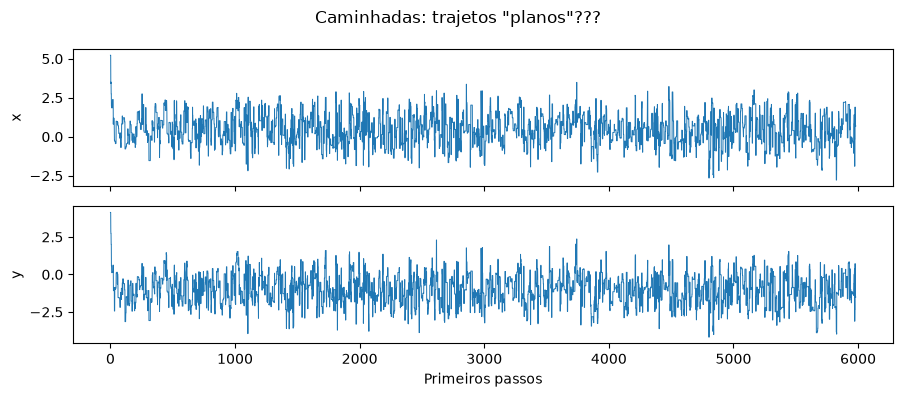

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
n_show = min(10000, len(chain))
for ax, i, name in zip(axes, range(2), ["x", "y"]):
    ax.plot(chain[:n_show, i], lw=0.7)
    ax.set_ylabel(name)
axes[-1].set_xlabel("Primeiros passos")
fig.suptitle("Caminhadas: trajetos \"planos\"???")
plt.tight_layout()
plt.show()

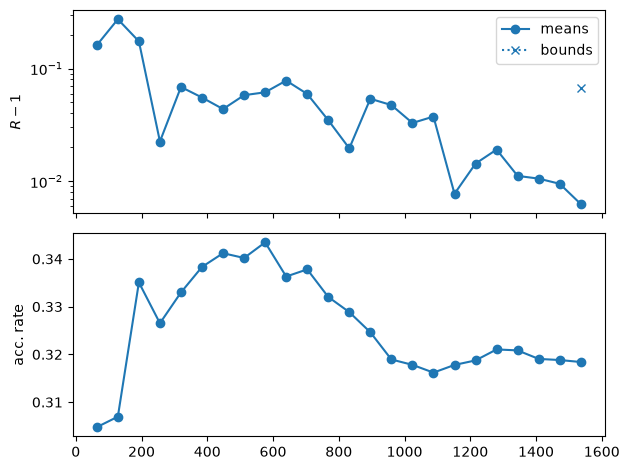

In [38]:
plot_progress("results_ex1/exemplo1")
plt.tight_layout()
plt.show()

x: tau = 9.3 passos, ESS = 450 com N = 4188
y: tau = 9.6 passos, ESS = 438 com N = 4188


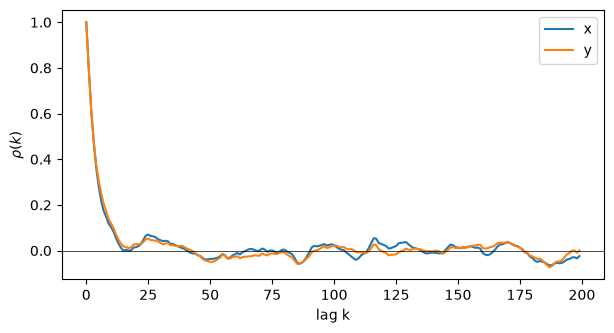

In [39]:
def autocorr_fn(x):
    x = np.asarray(x) - np.mean(x)
    n = len(x)
    f = np.fft.rfft(x, n=2 * n)
    acf = np.fft.irfft(f * np.conjugate(f))[:n]
    return acf / acf[0]

def tau_int(x, c=5.0):
    rho = autocorr_fn(x)
    taus = 2.0 * np.cumsum(rho) - 1.0
    window = np.arange(len(taus)) < c * taus
    m = np.argmin(window) if not window.all() else len(taus) - 1
    return taus[m]

burn = int(0.3 * len(chain))
c = chain[burn:]

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, name in enumerate(["x", "y"]):
    rho = autocorr_fn(c[:, i])
    ax.plot(rho[:200], label=name)
    tau = tau_int(c[:, i])
    print(f"{name}: tau = {tau:.1f} passos, ESS = {len(c)/tau:.0f} com N = {len(c)}")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("lag k"); ax.set_ylabel(r"$\rho(k)$"); ax.legend()
plt.show()

In [40]:
print(open("results_ex1/exemplo1.covmat").read())
print("Verdadeira covariancia:\n", cov)

burn = int(0.3 * len(chain))
c = chain[burn:]
gd_cov = np.cov(c.T)
print("Cov da amostra (após burn-in):\n", gd_cov)

# x y
1.013069725051408243e+00 9.288941659450884458e-01
9.288941659450884458e-01 1.041783332270577178e+00

Verdadeira covariancia:
 [[1.  0.9]
 [0.9 1. ]]
Cov da amostra (após burn-in):
 [[1.01425195 0.93336136]
 [0.93336136 1.05040832]]


[root] *WARNING* outlier fraction 0.011458333333333333 


[root] *WARNING* outlier fraction 0.050595238095238096 


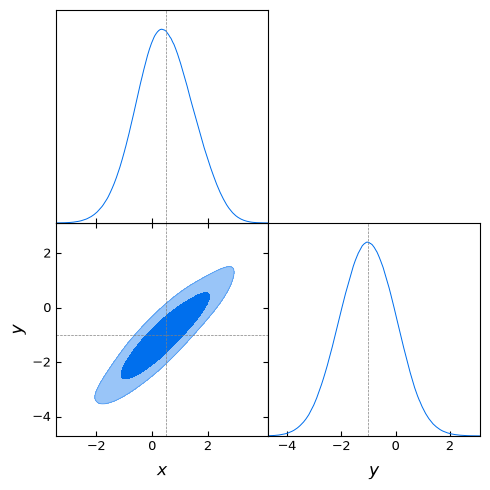

In [41]:
gd = MCSamplesFromCobaya(updated_info, samples)
burn = 0.3
gd.removeBurn(burn)
#print(gd.getMargeStats())

g = gdplt.get_subplot_plotter(width_inch=5)
g.triangle_plot(gd, ["x", "y"], filled=True, markers={"x": mean[0], "y": mean[1]})
plt.show()

### Coisas pra testar

- Mudar `"proposal"` para 0.01, depois para 20, e configurar `"learn_proposal": False`. O que acontece com o acceptance rate e $\tau$?.
- Mudar a correlaçao para 0.99. Quantos passos de adaptação são precisos agora?
- Ver R-1 ao longo da cadeia.
- Mudar burn-in nos plots.

# emcee : Ensemble sampling

https://emcee.readthedocs.io/en/stable/user/sampler/

Em vez de uma cadeia, evolui-se um conjunto de K “caminhantes”. A proposta para um walker usa os outros walkers como informação sobre a forma da distribuição.

### A ideia

No Metropolis-Hastings usual, evoluímos uma cadeia, e a proposta depende só do ponto atual. No *ensemble sampling* evoluímos um **conjunto de $K$ "caminhantes"** (*walkers*) $\{\theta_1, \dots, \theta_K\}$ ao mesmo tempo, e a proposta para cada walker usa os outros walkers como informação sobre a forma da distribuição. Formalmente, o estado da cadeia é o conjunto inteiro, que vive no espaço produto e tem como alvo $\pi(\theta_1)\,\pi(\theta_2)\cdots\pi(\theta_K)$. Cada walker, isoladamente, tem $\pi$ como distribuição de equilíbrio.

### O *stretch move*

É a proposta mais usada, e a base do pacote `emcee`. Para atualizar o walker $X_k$:

1. Escolha outro walker $X_j$ do conjunto (diferente de $X_k$).
2. Proponha um ponto sobre a reta que liga os dois:

$$
Y = X_j + Z\,(X_k - X_j), \qquad Z \sim g(z) \propto \frac{1}{\sqrt{z}}, \quad z \in \left[\tfrac{1}{a}, a\right],
$$

em que $a$ é um parâmetro de escala (tipicamente $a = 2$).

3. Aceite com probabilidade

$$
\alpha = \min\!\left(1,\; Z^{\,d-1}\,\frac{\pi(Y)}{\pi(X_k)}\right),
$$

em que $d$ é a dimensão. O fator $Z^{d-1}$ vem do jacobiano da transformação e garante o balanço detalhado.

Para poder paralelizar, o `emcee` divide os walkers em duas metades e atualiza uma metade condicionada à outra. Os walkers de uma mesma metade podem então ser avaliados em paralelo.

### Por que usar: invariância afim

Se transformarmos linearmente os parâmetros (rotação, mudança de escala, cisalhamento), o desempenho do método não muda. Por isso ele não precisa de matriz de covariância nem de ajuste do tamanho do passo: degenerescências lineares entre parâmetros são tratadas automaticamente, porque os walkers já se espalham ao longo delas. Os únicos ajustes são o número de walkers e o parâmetro $a$.

###

- **Número de walkers.** O mínimo é $2d$.
- **Inicialização.** Os walkers devem começar espalhados e em uma região plausível. Uma "bolinha" pequena no espaço de parâmetros leva muito tempo para se expandir até o tamanho do posterior.
- **Dimensão alta.** A aceitação do stretch move cai com $d$ (o fator $Z^{d-1}$ pesa) e o método perde eficiência.
- **Curvaturas não lineares e multimodalidade.** 
- **Sem aproveitar custos heterogêneos.** Não há equivalente de parâmetros rápidos/lentos nem de *dragging*, e cada atualização de walker reavalia o likelihood completo.
- **Diagnóstico.** Os walkers de um mesmo conjunto interagem, então não são cadeias independentes e o Gelman-Rubin é só indicativo. O diagnóstico recomendado é o tempo de autocorrelação $\tau$ (por exemplo, verificar $N \gtrsim 50\,\tau$).

### Relação com o Metropolis-Hastings

O ensemble sampling também é, formalmente, um MH no espaço estendido dos walkers. A diferença está na **proposta**: o MH usual usa uma proposta que depende só do ponto atual (a covariância, quando adaptativa, é aprendida da cadeia), e o ensemble usa uma proposta construída com a população de walkers.

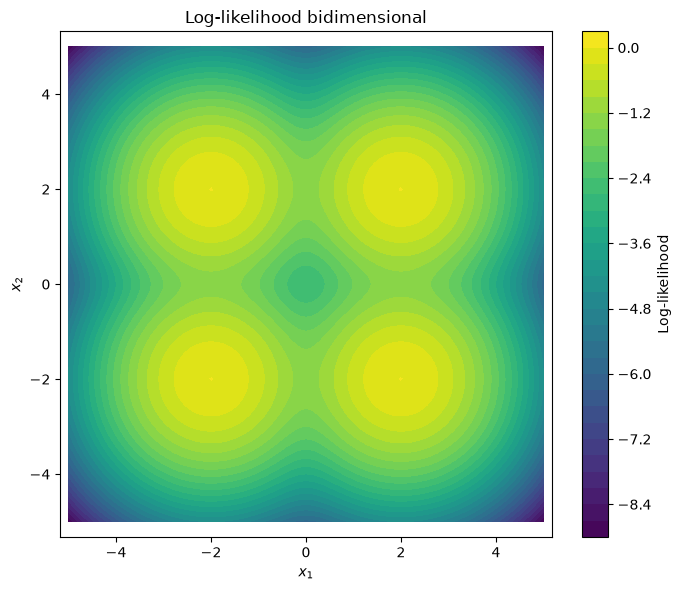

In [42]:
def logprob(x):
    return np.sum(
        np.logaddexp(
            -0.5 * (x - 2)**2,
            -0.5 * (x + 2)**2,
        )
    )

# Crear la cuadrícula bidimensional
x1 = np.linspace(-5, 5, 200)
x2 = np.linspace(-5, 5, 200)
X1, X2 = np.meshgrid(x1, x2)

# Evaluar la log-likelihood en cada punto
Z = np.zeros_like(X1)

for i in range(len(x1)):
    for j in range(len(x2)):
        Z[j, i] = logprob(np.array([X1[j, i], X2[j, i]]))

# Gráfico de contornos
plt.figure(figsize=(7, 6))
plt.contourf(X1, X2, Z, levels=30, cmap="viridis")
plt.colorbar(label="Log-likelihood")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Log-likelihood bidimensional")
plt.axis("equal")
plt.tight_layout()
plt.show()

In [43]:
# --------------------------------
# Likelihood
# --------------------------------

def logprob(x):
    return np.sum(
        np.logaddexp(
            -0.5 * (x - 2)**2,
            -0.5 * (x + 2)**2,
        )
        - 0.5 * np.log(2 * np.pi)
        - np.log(2)
    )

# --------------------------------
# Montamos emcee
# --------------------------------

ndim = 2
nwalkers = 32
nsteps = 5000

# Aqui os walkers comecam perto de um dos modos
rng = np.random.default_rng(42)
p0 = np.array([2.0, 2.0]) + 0.1 * rng.normal(
    size=(nwalkers, ndim)
)

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    logprob
)

# --------------------------------
# Rodar as cadeias
# --------------------------------

sampler.run_mcmc(p0, nsteps, progress=True)

# Extrair as cadeias
chains = sampler.get_chain()
print("Shape:", chains.shape)
# (nsteps, nwalkers, ndim)

100%|████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:02<00:00, 2005.37it/s]

Shape: (5000, 32, 2)


Como andaram os walkers?

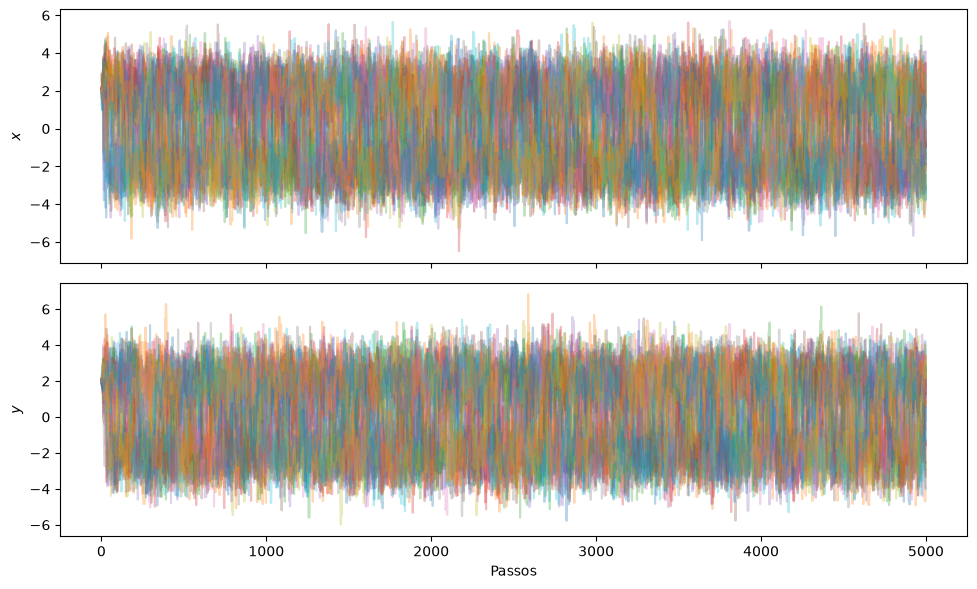

In [44]:
fig, axes = plt.subplots(
    ndim, figsize=(10, 6), sharex=True
)

labels = [r"$x$", r"$y$"]

# (nsteps, nwalkers, ndim)
for i in range(ndim):
    axes[i].plot(chains[:, :, i], alpha=0.3)
    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("Passos")
plt.tight_layout()
plt.show()

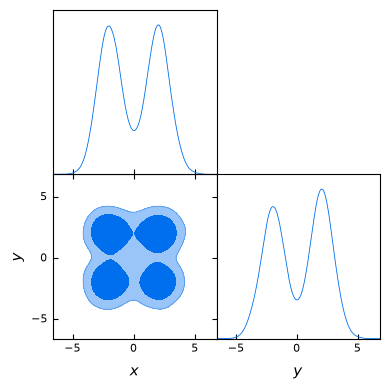

In [45]:
flat_samples = sampler.get_chain(
    discard=1000,
    thin=10,
    flat=True
)

# Criar as amostras do GetDist
samples = MCSamples(
    samples=flat_samples,
    names=['x', 'y'],
    labels=[r'x', r'y']
)

# Gerar o triangle plot
g = gdplt.get_subplot_plotter()

g.triangle_plot(
    samples,
    params=['x', 'y'],
    filled=True
)

plt.show()

In [16]:
chains = sampler.get_chain(discard=1500)

nsteps, nwalkers, ndim = chains.shape

tau = sampler.get_autocorr_time(discard=1500)

ess = nsteps * nwalkers / tau

for i in range(ndim):
    print(f"Parâmetro {i}:")
    print(f"  tau = {tau[i]:.2f}")
    print(f"  ESS ≈ {ess[i]:.0f}")

Parâmetro 0:
  tau = 60.64
  ESS ≈ 1847
Parâmetro 1:
  tau = 59.87
  ESS ≈ 1871


Aqui vamos usar como criterio a longitude da cadeia em unidades de $\tau$. Costuma-se considerar suficiente uma cadeia de $50\tau$

In [46]:
nsteps = chains.shape[0]
print("Nsteps / tau =", nsteps / tau)

Nsteps / tau = 522.7145842246332


## Diferentes 'moves' e tempos de autocorrelação

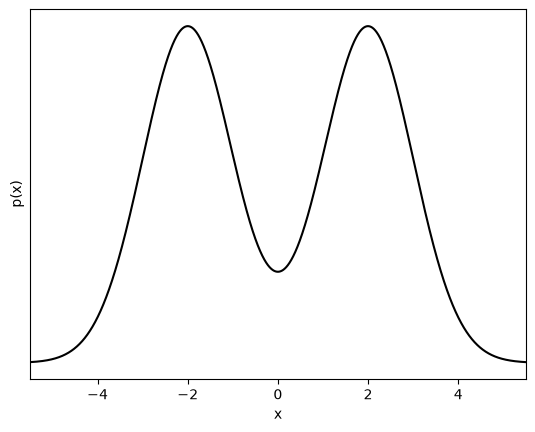

In [47]:
def logprob(x):
    return np.sum(
        np.logaddexp(
            -0.5 * (x - 2) ** 2,
            -0.5 * (x + 2) ** 2,
        )
        - 0.5 * np.log(2 * np.pi)
        - np.log(2)
    )

x = np.linspace(-5.5, 5.5, 5000)
plt.plot(x, np.exp(list(map(logprob, x))), "k")
plt.yticks([])
plt.xlim(-5.5, 5.5)
plt.ylabel("p(x)")
plt.xlabel("x");

In [48]:
np.random.seed(589403)

init = np.random.randn(32, 1)
nwalkers, ndim = init.shape

sampler0 = emcee.EnsembleSampler(nwalkers, ndim, logprob)
sampler0.run_mcmc(init, 5000)

print(
    "Autocorrelation time: {0:.2f} steps".format(
        sampler0.get_autocorr_time()[0]
    )
)

Autocorrelation time: 40.03 steps


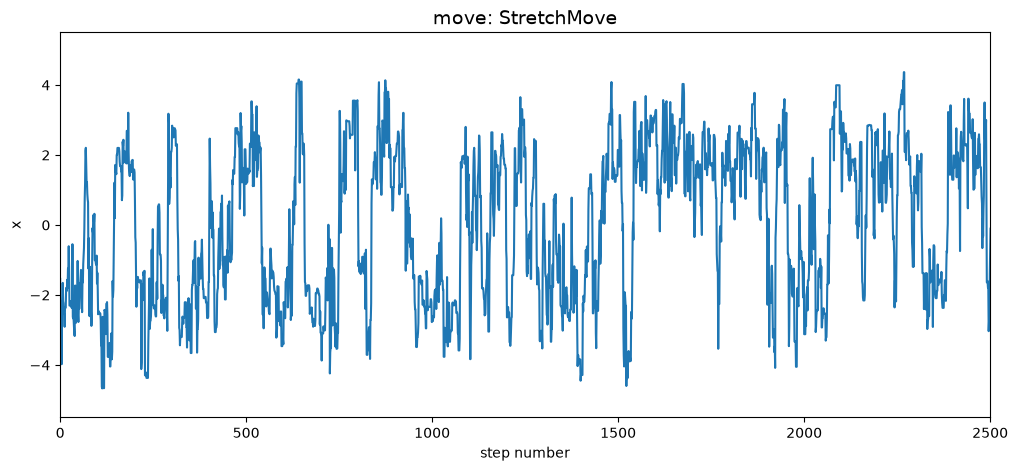

In [49]:
plt.figure(figsize=(12, 5))
plt.plot(sampler0.get_chain()[:, 0, 0])
plt.xlim(0, 2500)
plt.ylim(-5.5, 5.5)
plt.title("move: StretchMove", fontsize=14)
plt.xlabel("step number")
plt.ylabel("x");

Autocorrelation time: 6.37 steps


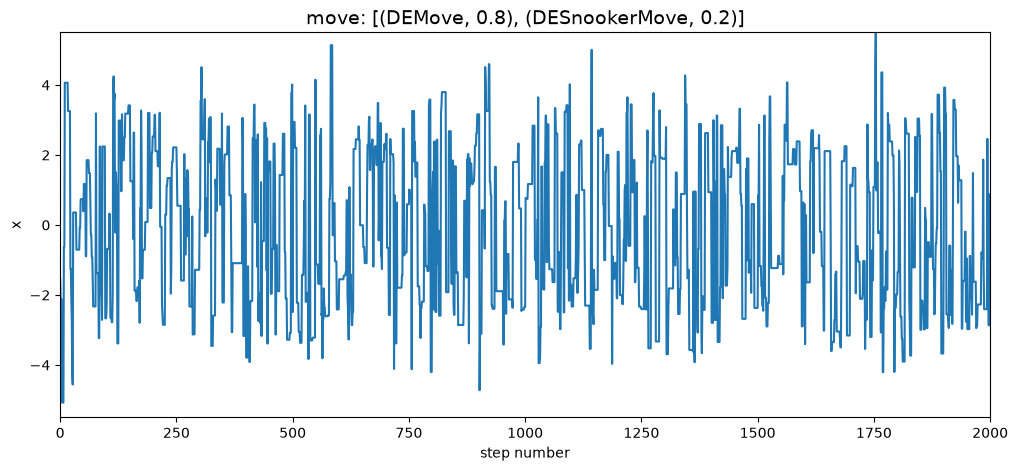

In [50]:
np.random.seed(93284)

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    logprob,
    moves=[
        (emcee.moves.DEMove(), 0.8),
        (emcee.moves.DESnookerMove(), 0.2),
    ],
)
sampler.run_mcmc(init, 5000)

print(
    "Autocorrelation time: {0:.2f} steps".format(
        sampler.get_autocorr_time()[0]
    )
)
plt.figure(figsize=(12, 5))
plt.plot(sampler.get_chain()[:, 0, 0])
plt.xlim(0, 2000)
plt.ylim(-5.5, 5.5)
plt.title("move: [(DEMove, 0.8), (DESnookerMove, 0.2)]", fontsize=14)
plt.xlabel("step number")
plt.ylabel("x");

# Likelihood: comparando dados com um modelo teórico

## Dados: Supernovas tipo Ia e SH0ES

### A ideia

Temos um vetor de $N$ medidas $d$ (por exemplo, magnitudes de supernovas em diferentes redshifts) e um modelo teórico que, para um conjunto de parâmetros $\theta$, prevê um vetor $m(\theta)$. A *likelihood* mede quão provável é observar $d$ se o modelo com parâmetros $\theta$ for verdadeiro. Se os erros de medida são gaussianos, com matriz de covariância $C$, ela é

$$
\mathcal{L}(d \mid \theta) \;=\; \frac{1}{\sqrt{(2\pi)^N \det C}}\;
\exp\!\left[-\frac{1}{2}\,\big(d - m(\theta)\big)^{\!T}\, C^{-1}\,\big(d - m(\theta)\big)\right].
$$

Em logaritmo, e descartando constantes que não dependem de $\theta$:

$$
\ln\mathcal{L}(\theta) \;=\; -\tfrac{1}{2}\,\chi^2(\theta) + \text{const}, \qquad
\chi^2(\theta) = r^T C^{-1} r, \quad r = d - m(\theta).
$$

O vetor $r$ é o **resíduo**: a diferença entre o dado e o que o modelo prevê.

### Casos particulares

- **Erros independentes:** $C$ é diagonal e $\chi^2 = \sum_i \dfrac{(d_i - m_i)^2}{\sigma_i^2}$. Cada ponto contribui separadamente.
- **Erros correlacionados:** $C$ tem termos fora da diagonal.

### Cuidados

- **Quando as constantes importam?** Descartar $\det C$ e $(2\pi)^N$ só é legítimo se $C$ não depende de $\theta$. Se a covariância depende dos parâmetros, ou se você vai comparar modelos pela evidência, o termo $-\tfrac{1}{2}\ln\det C$ deve ser mantido.
- **Parâmetros de nuisance** Quantidades que afetam os dados mas não interessam fisicamente (calibração, offsets, foregrounds) entram em $\theta$ e são marginalizadas depois.
- **Gaussianidade é uma aproximação** Para contagens pequenas usa-se a likelihood de Poisson, e para erros assimétricos ou caudas pesadas, outras distribuições.
- **Verificação rápida** No melhor ajuste, $\chi^2/k$ deve ficar perto de 1 (sendo $k$ o número de graus de liberdade). Valores muito maiores sugerem modelo inadequado ou erros subestimados, e muito menores, erros superestimados.

In [22]:
from mymodule import load_SN_data

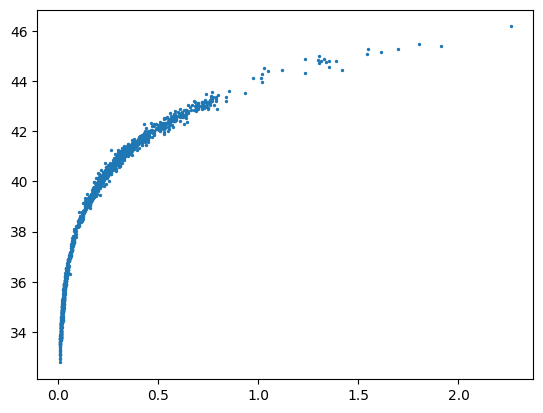

In [ ]:
# Carregar e plotar os dados
data = load_SN_data()
C_inv = np.linalg.inv(data['cov'])
plt.scatter(data['zHD'], data['MU'], s=2)

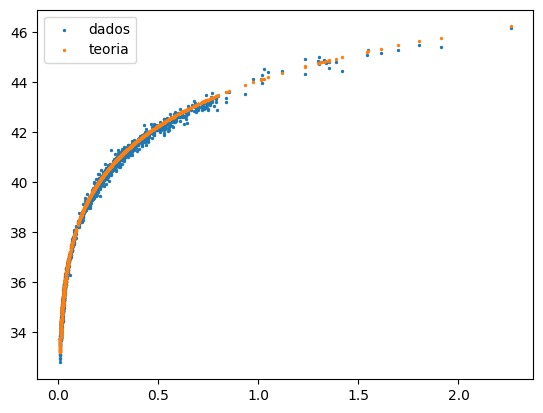

In [24]:
# TEORIA : Modelo cosmologico: LambdaCDM
def vec_teoria(z, theta):
    Om,OL,H0 = theta
    cosmo = LambdaCDM(Om0=Om, Ode0=OL, H0=H0)
    lum_dist = cosmo.comoving_transverse_distance(z).value*(1+z)
    mu = 5*np.log10(lum_dist)+25
    return mu

#plt.scatter(data['zHD'], data['mB']+19.4, s=2, label='dados')
plt.scatter(data['zHD'], data['MU'], s=2, label='dados')
plt.scatter(data['zHD'], vec_teoria(data['zHD'], [0.33,0.67, 70]), s=2, label='teoria')
plt.legend()

faça o seu emcee!